# Convex equilibrium potentials for Monge–Ampère — all experiments

Companion notebook for *Convex Equilibrium Potentials for Monge–Ampère: Curvature Bounds and A Posteriori Evaluation* (E. Vázquez, Y. Lu, T. Nowicki).

Everything runs on **CPU in float64**, with rigorous enclosures computed by **Arb at 128 bits** (python-flint). Run the cells from top to bottom.

| Part | What it does | Paper | Code |
|---|---|---|---|
| A | Unit tests of the certificate and E0–E1 validation of the equilibrium derivatives | Sec. 3, 5; App. A | `test_certification.py`, `validation_e0_e1.py` |
| B | Six trained models (P1/P2 × 3 seeds), depth sweep, 73,728 Arb point certificates, timing, complete disk and boundary covers, 120-network consistency check | Sec. 8.1–8.6 | `run.py` |
| C | Bounded post hoc refinement of the P2 seed-2 cover and barrier bounds | Sec. 8.6, Fig. 4, Table 4 | `refine_saved.py` |
| D | Extended experiments X1–X6 (see below) | new | `extended.py` |
| E | Tables and figures | | |

**Extended experiments (Part D)**

| ID | Question |
|---|---|
| X1 | Near-critical contraction: how do accuracy, curvature constants and certification cost behave as $q \to 1$ ($q = 0.7, 0.9, 0.95, 0.98$, with $\|W\|_\infty = q$ exactly)? |
| X2 | How does an explicit ICNN of the same size (211 vs 207 parameters), trained with the same protocol, compare? |
| X3 | Harder problems: P3 (radial exponential, Nyström–Vestberg Ex. 4.1 on the disk) and P4 (right-hand side vanishing on a line), with the full certification pipeline |
| X4 | How tight can the uniform residual certificate get? $R$ versus number of certified boxes and CPU time |
| X5 | Classical reference: finite-difference Newton solver on the same problems |
| X6 | How does the cost of float64 and Arb certification grow with the width $m$? |

**Profiles.** `PROFILE = "smoke"` checks the whole chain in a few minutes with tiny settings; its numbers are *not* results. `PROFILE = "full"` runs the protocols reported in the paper and in the extended study. Every stage is resumable: re-running a cell skips completed work, and a changed configuration is refused in an existing output folder.

**Indicative full-profile durations on one CPU thread** (they vary with the machine): Part B several hours; Part C a few minutes; X1 about 2–3 hours (dominated by $q = 0.98$, which trains through 877 unrolled iterations); X2–X3 about 1–2 hours; X4 about 30 minutes; X5 under a minute; X6 about 1 hour.

## 1. Configuration

In [27]:
PROFILE = "full"          # "smoke" (quick check of the full chain) or "full" (results)
RUN_TESTS = False           # Part A
RUN_PAPER = False          # Part B
RUN_REFINEMENT = False      # Part C (full profile only; needs the completed Part B archive)
RUN_EXTENDED = True        # Part D
EXTENDED_EXPERIMENTS = ["X1", "X3", "X2", "X4", "X5", "X6"]   # any subset; X3 before X2/X4 reuses its P3 models
USE_DRIVE = True          # Colab: keep results in Google Drive across disconnections
RUN_NAME = "full1"            # change it to start an independent run
REPO_URL = "https://github.com/EdisonVazquezG/monge-ampere-equilibrium.git"
assert PROFILE in ("smoke", "full")

## 2. Code and output folders

The code lives in the `code/` folder of the repository. In Colab the repository is cloned automatically if it is not present.

In [28]:
from pathlib import Path
import os, subprocess, sys
from google.colab import drive
drive.mount("/content/drive")

BASE = Path("/content/drive/MyDrive/MongeAmpere_Equilibrium/v2")   # carpeta donde está todo

hits = sorted(BASE.rglob("run.py"))
assert hits, f"No encuentro run.py dentro de {BASE}"
CODE = hits[0].parent
REPO = CODE.parent if CODE.name == "code" else CODE
print("Code:", CODE)

OUT = Path("/content/drive/MyDrive/MongeAmpere_Equilibrium") / ("results_" + RUN_NAME)
OUT.mkdir(parents=True, exist_ok=True)
PAPER_DIR = OUT / f"paper_{PROFILE}"
EXTENDED_DIR = OUT / f"extended_{PROFILE}"
print("Results:", OUT)

needed = ["numerics.py", "rigorous.py", "coverage_check.py", "run.py", "extended.py",
          "refine_saved.py", "test_certification.py", "validation_e0_e1.py", "check_bounds.py",
          "original_pilots.py"]
missing = [f for f in needed if not (CODE / f).exists()]
print("Faltan:", missing if missing else "nada, están todos")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Code: /content/drive/MyDrive/MongeAmpere_Equilibrium/v2
Results: /content/drive/MyDrive/MongeAmpere_Equilibrium/results_full1
Faltan: nada, están todos


In [32]:
!ls /content/drive/MyDrive/MongeAmpere_Equilibrium/v2

check_bounds.py		   icnn_certification.py  rigorous.py
config_extended.json	   METHODS.txt		  run.py
config_full.json	   numerics.py		  source_provenance.json
coverage_check.py	   original_pilots.py	  test_certification.py
extended.py		   __pycache__		  validation_e0_e1.py
historical_baselines.json  refine_saved.py


## 3. Dependencies

PyTorch is installed from the CPU wheel index; NumPy, Matplotlib, SciPy, mpmath and python-flint (Arb) follow `requirements.txt`. All experiments run in separate processes with one BLAS thread.

In [ ]:
import importlib.util

def pip_install(*packages):
    cmd = [sys.executable, "-m", "pip", "install", *packages]
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0:
        r = subprocess.run(cmd + ["--break-system-packages"], capture_output=True, text=True)
    if r.returncode != 0:
        print("FAILED:", " ".join(packages))
        print(r.stdout[-3000:])
        print(r.stderr[-3000:])
        raise RuntimeError(f"pip could not install {packages}")
    print("OK:", " ".join(packages))

print(sys.version)
if importlib.util.find_spec("torch") is None:
    pip_install("torch", "--index-url", "https://download.pytorch.org/whl/cpu")
for pkg in ["numpy>=2.0", "matplotlib>=3.8", "scipy>=1.11", "mpmath", "python-flint==0.8.0", "pandas"]:
    pip_install(pkg)

ENV = dict(os.environ, OPENBLAS_NUM_THREADS="1", OMP_NUM_THREADS="1", MKL_NUM_THREADS="1")

def run_script(*args):
    cmd = [sys.executable, "-u", *map(str, args)]
    print("$", " ".join(cmd[2:]), flush=True)
    proc = subprocess.Popen(cmd, cwd=CODE, env=ENV, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for line in proc.stdout:
        print(line, end="")
    if proc.wait() != 0:
        raise RuntimeError(f"{args[0]} failed with exit code {proc.returncode}")

subprocess.run([sys.executable, "-c", "import torch, numpy, flint, scipy; "
                "print('torch', torch.__version__, '| numpy', numpy.__version__, '| python-flint', flint.__version__)"], check=True)

3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
OK: numpy>=2.0
OK: matplotlib>=3.8
OK: scipy>=1.11
OK: mpmath
OK: python-flint==0.8.0
OK: pandas


CompletedProcess(args=['/usr/bin/python3', '-c', "import torch, numpy, flint, scipy; print('torch', torch.__version__, '| numpy', numpy.__version__, '| python-flint', flint.__version__)"], returncode=0)

## Part A — Validation

`test_certification.py` checks the Arb certificate against an independent 80-digit oracle, an exactly solvable separable case, autograd, outward export and gap detection in covers. `validation_e0_e1.py` checks the implicit input derivatives against autograd through an explicit weight-tied unroll and the a priori and residual state bounds (three random untrained networks).

In [ ]:
if RUN_TESTS:
    run_script("test_certification.py")
    run_script("validation_e0_e1.py", "--out", OUT / "validation_e0_e1")

$ test_certification.py
test_closed_form_separable (__main__.CertificationTests.test_closed_form_separable) ... ok
test_coupled_against_80_digit_oracle (__main__.CertificationTests.test_coupled_against_80_digit_oracle) ... ok
test_coverage_and_reject_gap (__main__.CertificationTests.test_coverage_and_reject_gap) ... ok
test_float_jets_match_original_autograd (__main__.CertificationTests.test_float_jets_match_original_autograd) ... Problem 2 data: verified.
ok
test_monotone_functions_wide_ball (__main__.CertificationTests.test_monotone_functions_wide_ball) ... ok
test_outward_export (__main__.CertificationTests.test_outward_export) ... ok

----------------------------------------------------------------------
Ran 6 tests in 2.208s

OK
$ validation_e0_e1.py --out /content/drive/MyDrive/MongeAmpere_Equilibrium/results_full1/validation_e0_e1
Seed 0: PASS | iterations=28 | residual=2.449e-13 | Hessian error=4.441e-16
Seed 1: PASS | iterations=25 | residual=2.978e-13 | Hessian error=2.748e-1

## Part B — Reproduction of the paper experiments

One command trains the six models (P1/P2, seeds 0–2; width 12, $q=0.7$, 32 unrolled iterations, Adam then L-BFGS), evaluates them at the numerical equilibrium, sweeps the depth $L\in\{4,\dots,32\}$, certifies every point/depth pair with Arb, times fixed and adaptive evaluation, builds complete covers of the disk and its boundary, and reruns the 120-network consistency check (Table 1).

`RUN_STATUS.json` reports what was actually completed. `coverage_complete` and `residual_target_met` are different properties: an exhausted budget keeps a valid but wider bound.

In [ ]:
if RUN_PAPER:
    run_script("run.py", "--profile", PROFILE, "--out", PAPER_DIR)

$ run.py --profile full --out /content/drive/MyDrive/MongeAmpere_Equilibrium/results_full1/paper_full
RUN P1_seed0 train
Problem 2 data: verified.
Initial backward: PASS
Adam    1 | PDE MSE=7.497e-01 | boundary MSE=3.614e-01
Adam  100 | PDE MSE=3.139e-01 | boundary MSE=1.541e-03
Adam  200 | PDE MSE=8.588e-02 | boundary MSE=6.904e-04
Adam  300 | PDE MSE=3.284e-02 | boundary MSE=6.180e-04
Adam  400 | PDE MSE=1.721e-02 | boundary MSE=3.959e-04
Adam  500 | PDE MSE=1.076e-02 | boundary MSE=2.232e-04
Adam  600 | PDE MSE=8.235e-03 | boundary MSE=1.197e-04
Adam  700 | PDE MSE=4.578e-03 | boundary MSE=5.230e-05
Adam  800 | PDE MSE=2.748e-03 | boundary MSE=4.144e-05
Adam  900 | PDE MSE=3.810e-03 | boundary MSE=3.577e-05
Adam 1000 | PDE MSE=3.053e-03 | boundary MSE=3.183e-05
Adam 1100 | PDE MSE=3.507e-03 | boundary MSE=2.156e-05
Adam 1200 | PDE MSE=2.622e-03 | boundary MSE=2.719e-05
L-BFGS evaluation   1 | PDE MSE=2.987e-03 | boundary MSE=2.672e-05
L-BFGS evaluation  20 | PDE MSE=1.725e-03 | boun

## Part C — Refinement of the P2 seed-2 cover

Subdivides only the boxes whose certified residual exceeds 0.25 (depth 8, then 9), keeping the boundary certificates and the model unchanged, and evaluates the explicit barrier bound $B_\partial + \sqrt{R}/2$ for all six covers. It reads the Part B archive and verifies its hashes first. This part needs the **full** profile.

In [ ]:
if RUN_REFINEMENT and PROFILE == "full":
    run_script("refine_saved.py", "--source-zip", str(PAPER_DIR) + "_results.zip",
               "--out", OUT / "refinement_P2_seed2")
elif RUN_REFINEMENT:
    print("Skipped: the refinement uses the completed full-profile archive of Part B.")

$ refine_saved.py --source-zip /content/drive/MyDrive/MongeAmpere_Equilibrium/results_full1/paper_full_results.zip --out /content/drive/MyDrive/MongeAmpere_Equilibrium/results_full1/refinement_P2_seed2
stage_depth8 splits 100 child boxes 344 seconds 6.0
stage_depth8 splits 200 child boxes 681 seconds 12.1
stage_depth8 splits 300 child boxes 1060 seconds 18.5
stage_depth8 splits 400 child boxes 1451 seconds 25.5
stage_depth8 splits 500 child boxes 1846 seconds 32.6
{
  "pde_residual_uniform_upper": 0.2549719355448705,
  "boundary_error_uniform_upper": 0.009988816118341943,
  "u_error_uniform_upper_manufactured": 0.04675309341565913,
  "solution_error_barrier_upper": 0.26246254521944595,
  "solution_error_best_upper": 0.04675309341565913,
  "stage": "stage_depth8",
  "coverage_complete": true,
  "roundoff_enclosed": true,
  "residual_target": 0.25,
  "residual_target_met": false,
  "boundary_target_met": true,
  "stop_reason": "eligible_boxes_exhausted",
  "retained_leaves": 15933,
  "di

## Part D — Extended experiments

P1/P2 models from Part B are reused when available (`--paper-run`); otherwise the experiments train what they need. Each experiment writes a `table_X*.csv`, a figure and per-model folders with parameters, training history and certificates.

*X5 note.* The finite-difference baseline assigns the exact manufactured values to stencil nodes outside the disk, which favours it; it is a reference for the accuracy scale, not a like-for-like competitor.

In [ ]:
if RUN_EXTENDED:
    args = ["extended.py", "--profile", PROFILE, "--out", EXTENDED_DIR, "--experiments", *EXTENDED_EXPERIMENTS]
    if PAPER_DIR.exists():
        args += ["--paper-run", PAPER_DIR]
    run_script(*args)

$ extended.py --profile full --out /content/drive/MyDrive/MongeAmpere_Equilibrium/results_full1/extended_full --experiments X1 X3 X2 X4 X5 X6 --paper-run /content/drive/MyDrive/MongeAmpere_Equilibrium/results_full1/paper_full
Problem 2 data: verified.
===== X1 =====
/content/drive/MyDrive/MongeAmpere_Equilibrium/v2/extended.py:242: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  hessian_error = float((H - Href).abs().max())
P2_q0.7_seed0 Adam 1: PDE=2.149e+00 boundary=1.101e+00
P2_q0.7_seed0 Adam 100: PDE=1.229e+00 boundary=4.954e-03
P2_q0.7_seed0 Adam 200: PDE=4.929e-01 boundary=1.947e-03
P2_q0.7_seed0 Adam 300: PDE=9.094e-02 boundary=2.938e-04
P2_q0.7_seed0 Adam 400: PDE=3.512e-02 boundary=6.912e-05
P2_q0.7_seed0 Adam 500: PDE=1.699e-02 boundary=3.181e-05
P2_q0.7_seed0 Adam 600: PDE=1.231e-02 bo

## PART F - ICNN Certification

In [33]:
X7_DIR = OUT / "X7_icnn_certification_full"
run_script("icnn_certification.py", "--selftest",
           "--extended-run", EXTENDED_DIR, "--paper-run", PAPER_DIR)          # prueba rápida, segundos
run_script("icnn_certification.py", "--profile", "full",
           "--extended-run", EXTENDED_DIR, "--paper-run", PAPER_DIR,
           "--out", X7_DIR)                                                   # ~10 min

$ icnn_certification.py --selftest --extended-run /content/drive/MyDrive/MongeAmpere_Equilibrium/results_full1/extended_full --paper-run /content/drive/MyDrive/MongeAmpere_Equilibrium/results_full1/paper_full
Problem 2 data: verified.
selftest passed: box R = 0.8168317386906331 | observed |H| max = 2.1175042495642447 | naive bound = 182.03435442984198
$ icnn_certification.py --profile full --extended-run /content/drive/MyDrive/MongeAmpere_Equilibrium/results_full1/extended_full --paper-run /content/drive/MyDrive/MongeAmpere_Equilibrium/results_full1/paper_full --out /content/drive/MyDrive/MongeAmpere_Equilibrium/results_full1/X7_icnn_certification_full
Problem 2 data: verified.
A {'problem': 'P1', 'seed': 0, 'points': 32, 'icnn_arb_seconds_per_point': 0.0005997209062797992, 'icnn_det_enclosure_radius_max': 3.0100389280398523e-37, 'icnn_residual_upper_max': 0.03981840576660481, 'eq_arb_certificate_seconds_per_point': 0.0007342874687310541, 'eq_float_reference_seconds_per_point': 0.00033

table_X7A_pointwise.csv


,problem,seed,points,icnn_arb_seconds_per_point,icnn_det_enclosure_radius_max,icnn_residual_upper_max,eq_arb_certificate_seconds_per_point,eq_float_reference_seconds_per_point,eq_det_error_upper_max,eq_residual_upper_max
0,P1,0,32,0.000600,3.010039e-37,0.039818,0.000734,0.000339,1.031397e-11,0.043945
1,P1,1,32,0.000598,2.608576e-37,0.022790,0.000691,0.000338,1.210014e-11,0.022142
2,P1,2,32,0.000595,4.172928e-37,0.023758,0.000704,0.000362,8.897466e-12,0.034198
3,P2,0,32,0.000608,7.548570e-37,0.033477,0.000693,0.000358,1.766314e-11,0.059823
4,P2,1,32,0.000590,6.823088e-37,0.053320,0.000704,0.000369,1.367147e-11,0.052591
5,P2,2,32,0.000589,7.489437e-37,0.043156,0.000681,0.000355,1.509047e-11,0.038012
6,P3,0,32,0.000589,2.851552e-36,0.044311,0.000676,0.000334,4.449633e-11,0.139155
7,P3,1,32,0.000613,2.823717e-36,0.051395,0.000708,0.000334,4.011604e-11,0.059435
8,P3,2,32,0.000608,2.190153e-36,0.038584,0.000685,0.000338,4.438152e-11,0.046174


table_X7B_cover.csv


,problem,seed,model,sample_residual_max,R_over_sample_max,evaluated_boxes,retained_boxes,max_level,R_uniform,seconds
0,P1,0,equilibrium,0.045998,66.618850,100,78,4,3.064351,0.209317
1,P1,0,equilibrium,0.045998,40.233415,252,188,4,1.850667,0.508365
2,P1,0,equilibrium,0.045998,19.099016,500,369,5,0.878522,0.989490
3,P1,0,equilibrium,0.045998,14.857787,1000,739,5,0.683432,1.933506
4,P1,0,equilibrium,0.045998,7.751541,2000,1474,6,0.356557,3.873008
5,P1,0,equilibrium,0.045998,6.414863,4000,2967,6,0.295073,7.651727
6,P1,0,equilibrium,0.045998,3.595331,8002,5925,7,0.165379,15.490876
7,P1,0,equilibrium,0.045998,3.017859,16000,11912,7,0.138816,30.585052
8,P1,0,equilibrium,0.045998,1.809107,32001,23809,9,0.083216,61.696712
9,P1,0,icnn,0.041939,34.496336,100,77,4,1.446739,0.059381


table_X7C_depth.csv


,layers,parameters,problem,seed,u_relative_l2_sample,sample_residual_max,R_over_sample_max,one_box_seconds,naive_hessian_bound,evaluated_boxes,retained_boxes,max_level,R_uniform,seconds
0,3,211,P2,0,0.002337,0.067908,15.530474,0.000812,182.034354,1003,730,6,1.054637,0.607237
1,3,211,P2,0,0.002337,0.067908,7.017553,0.000812,182.034354,4001,2929,7,0.476545,2.415009
2,6,475,P2,0,0.003280,0.148040,17.719479,0.001605,4883.035284,1002,731,6,2.623192,1.342149
3,6,475,P2,0,0.003280,0.148040,6.766889,0.001605,4883.035284,4002,2938,7,1.001770,5.329568
4,12,1003,P2,0,0.004063,0.088836,43.151650,0.003069,52979.482826,1000,728,6,3.833406,2.681271
5,12,1003,P2,0,0.004063,0.088836,14.087579,0.003069,52979.482826,4000,2938,7,1.251480,10.783312


table_X7D_apriori.csv


,model,layers,max_row_sum_W,observed_max_abs_hessian_entry,naive_apriori_bound,bound_over_observed
0,icnn_P1_seed0,3,1.157447,2.056656,76.216052,37.058246
1,icnn_P1_seed1,3,1.419830,2.131808,100.519207,47.152099
2,icnn_P1_seed2,3,1.458272,2.043868,162.394883,79.454677
3,icnn_P2_seed0,3,1.664958,2.109525,182.034354,86.291623
4,icnn_P2_seed1,3,1.531908,2.111113,168.207255,79.677045
5,icnn_P2_seed2,3,1.705729,2.110109,204.555792,96.940849
6,icnn_P3_seed0,3,2.755240,3.332241,945.419561,283.718805
7,icnn_P3_seed1,3,2.503657,3.379976,867.093347,256.538333
8,icnn_P3_seed2,3,2.765986,3.347090,797.958322,238.403602
9,icnn_depth_L3,3,1.664958,2.109525,182.034354,86.291623


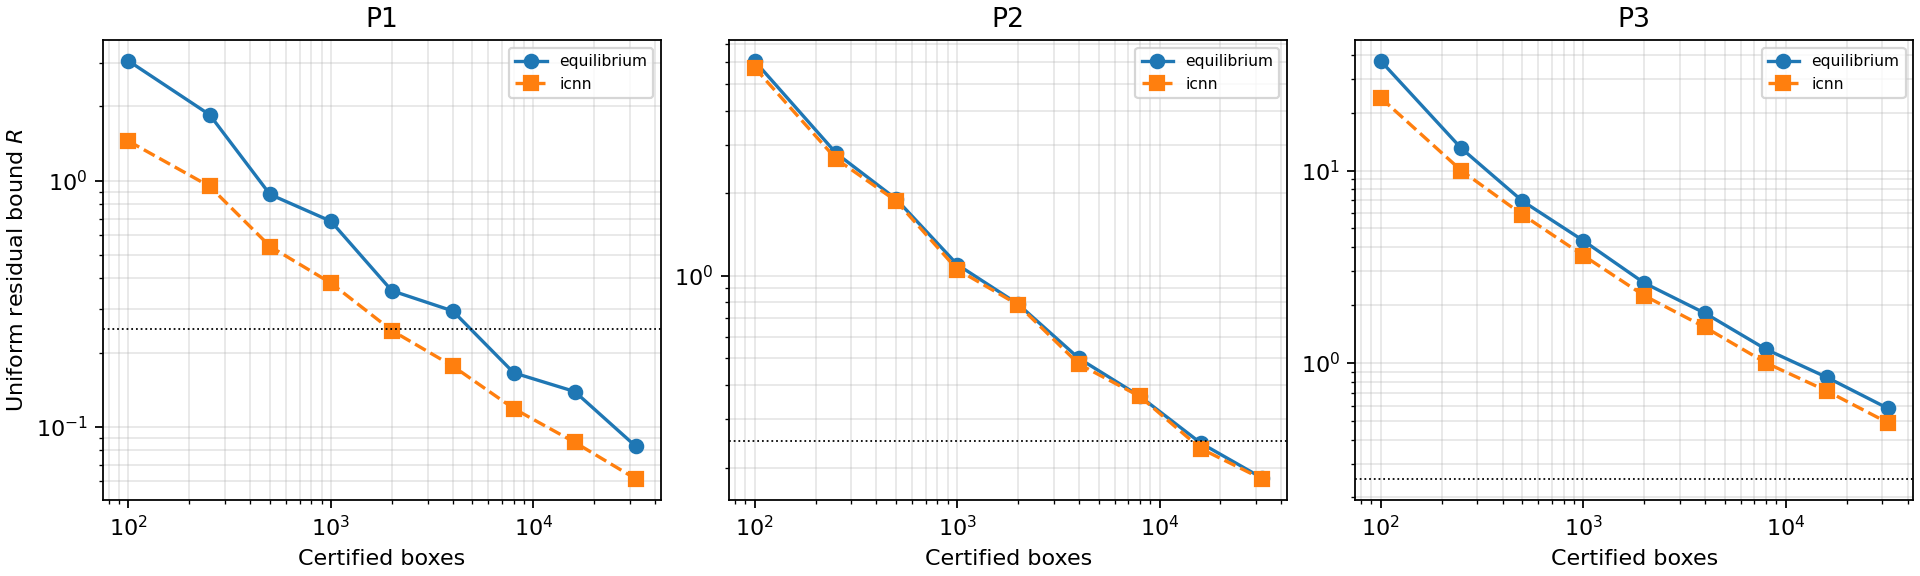

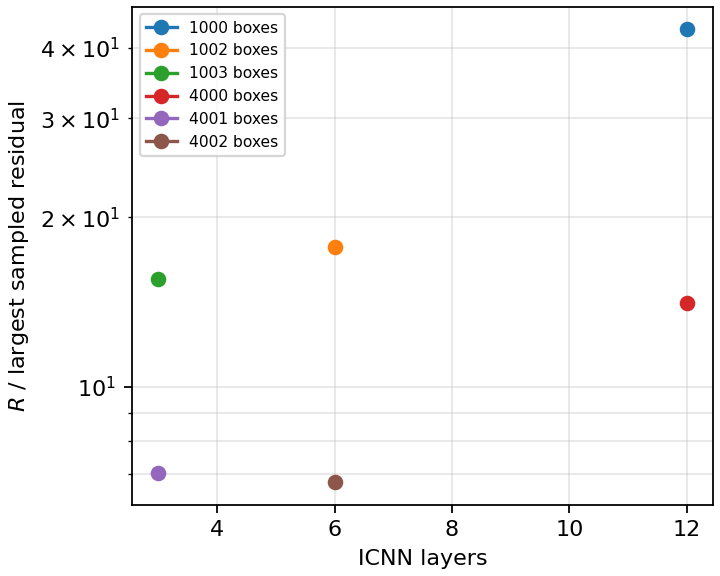

In [34]:
import pandas as pd
from IPython.display import display, Image
for n in ["table_X7A_pointwise.csv", "table_X7B_cover.csv", "table_X7C_depth.csv", "table_X7D_apriori.csv"]:
    print(n); display(pd.read_csv(X7_DIR / n))
for n in ["X7B_cover.png", "X7C_depth.png"]:
    display(Image(filename=str(X7_DIR / n)))

## Part E — Results

Tables are shown with pandas; figures are displayed if present. With `PROFILE = "smoke"` these outputs only confirm that the chain runs.

{
  "profile": "full",
  "trained_models": 6,
  "evaluated_models": 6,
  "float64_point_depth_pairs": 73728,
  "diagnostic_violations": 0,
  "arb_point_depth_pairs": 73728,
  "completed_domain_covers": 6,
  "full_pilot_pair_count_expected": 73728,
  "full_run_completed": true,
  "note": "Counts describe this execution, not reproduction of historical results by assertion."
}


**paper_full/table_pilots.csv**

,problem,seed,u_rmse,u_relative_l2_sample,u_max_abs_sample,pde_residual_rmse,pde_residual_max_abs_sample,boundary_rmse,boundary_max_abs_sample,min_hessian_eigenvalue_sample,W_norm_infinity_float64,reference_det_diagnostic_max,interpretation
0,P1,0,0.000964,0.002478,0.003927,0.010375,0.045998,0.002080,0.004150,0.457618,0.658400,6.430449e-12,Float64 sample diagnostics; not interval enclo...
1,P1,1,0.001131,0.002932,0.004275,0.012276,0.054896,0.001940,0.004564,0.475586,0.613541,6.470880e-12,Float64 sample diagnostics; not interval enclo...
2,P1,2,0.001216,0.003125,0.004958,0.015933,0.052482,0.002783,0.005022,0.456628,0.581746,6.976375e-12,Float64 sample diagnostics; not interval enclo...
3,P2,0,0.000967,0.003001,0.003804,0.018296,0.105285,0.002160,0.004173,0.980699,0.646561,1.364238e-11,Float64 sample diagnostics; not interval enclo...
4,P2,1,0.000913,0.002872,0.003799,0.016993,0.080306,0.001917,0.003872,1.000337,0.658008,1.519098e-11,Float64 sample diagnostics; not interval enclo...
5,P2,2,0.001007,0.003144,0.005618,0.019363,0.089144,0.002308,0.005954,0.980666,0.633032,1.656627e-11,Float64 sample diagnostics; not interval enclo...


**paper_full/table_domain.csv**

,problem,seed,coverage_complete,roundoff_enclosed,domain,parameters_sha256,pde_residual_uniform_upper,u_error_uniform_upper_manufactured,boundary_error_uniform_upper,residual_target_met,boundary_target_met,retained_leaves,examined_boxes,discarded_strictly_outside_boxes,boundary_arcs,seconds_this_invocation,precision_bits,method,interpretation
0,P1,0,True,True,closed unit disk,f8cf9da0190a043c88ba4829c183aa60027fe47b1a3bde...,0.232851,0.107236,0.010000,True,True,3332,4493,152,1616,50.036241,128,Uniform interval residuals on dyadic boxes; tr...,A valid bound need not meet the requested tole...
1,P1,1,True,True,closed unit disk,71f855a48030a8c001719180e926b763efc697e663977a...,0.244416,0.114533,0.010000,True,True,3332,4493,152,1751,52.100963,128,Uniform interval residuals on dyadic boxes; tr...,A valid bound need not meet the requested tole...
2,P1,2,True,True,closed unit disk,451938c0ba9b84ee0b50ef9426b9fa5cdf05b5a0eabb2c...,0.217256,0.110518,0.009995,True,True,3332,4493,152,1851,61.522747,128,Uniform interval residuals on dyadic boxes; tr...,A valid bound need not meet the requested tole...
3,P2,0,True,True,closed unit disk,35f21d757a2e392e71c733125bec4d5662c98819d9e15e...,0.249930,0.053947,0.009969,True,True,11351,15387,758,1533,143.466521,128,Uniform interval residuals on dyadic boxes; tr...,A valid bound need not meet the requested tole...
4,P2,1,True,True,closed unit disk,149d94fbe60042db15c94915d9a89f7f8baf11ce665563...,0.249997,0.065538,0.009999,True,True,11668,15813,768,1647,140.029568,128,Uniform interval residuals on dyadic boxes; tr...,A valid bound need not meet the requested tole...
5,P2,2,True,True,closed unit disk,a9d7cb82e5a69ae7071692c4830aeeef5a9ebdf302d37b...,0.437694,0.046753,0.009989,False,True,14584,19677,696,1412,170.519927,128,Uniform interval residuals on dyadic boxes; tr...,A valid bound need not meet the requested tole...


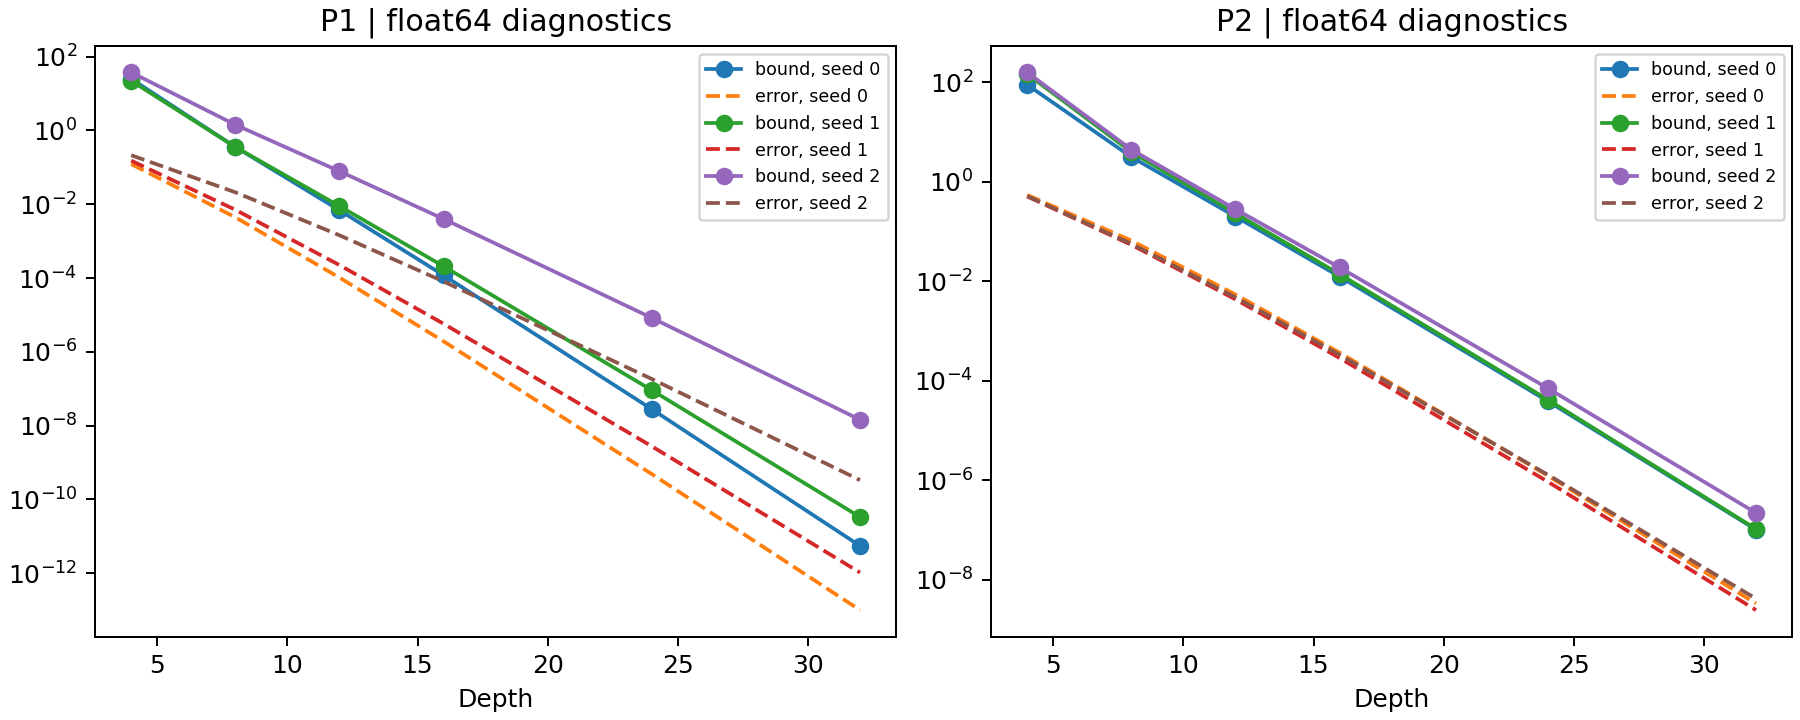

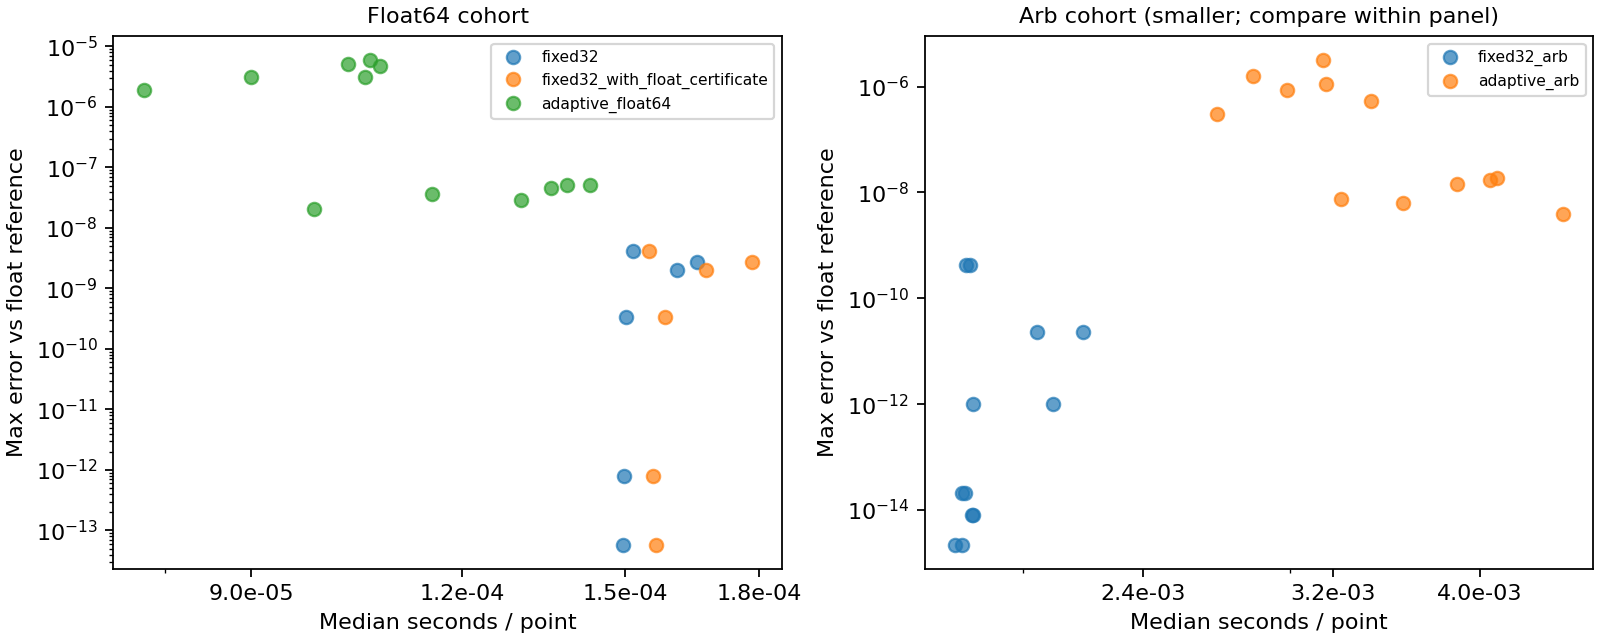

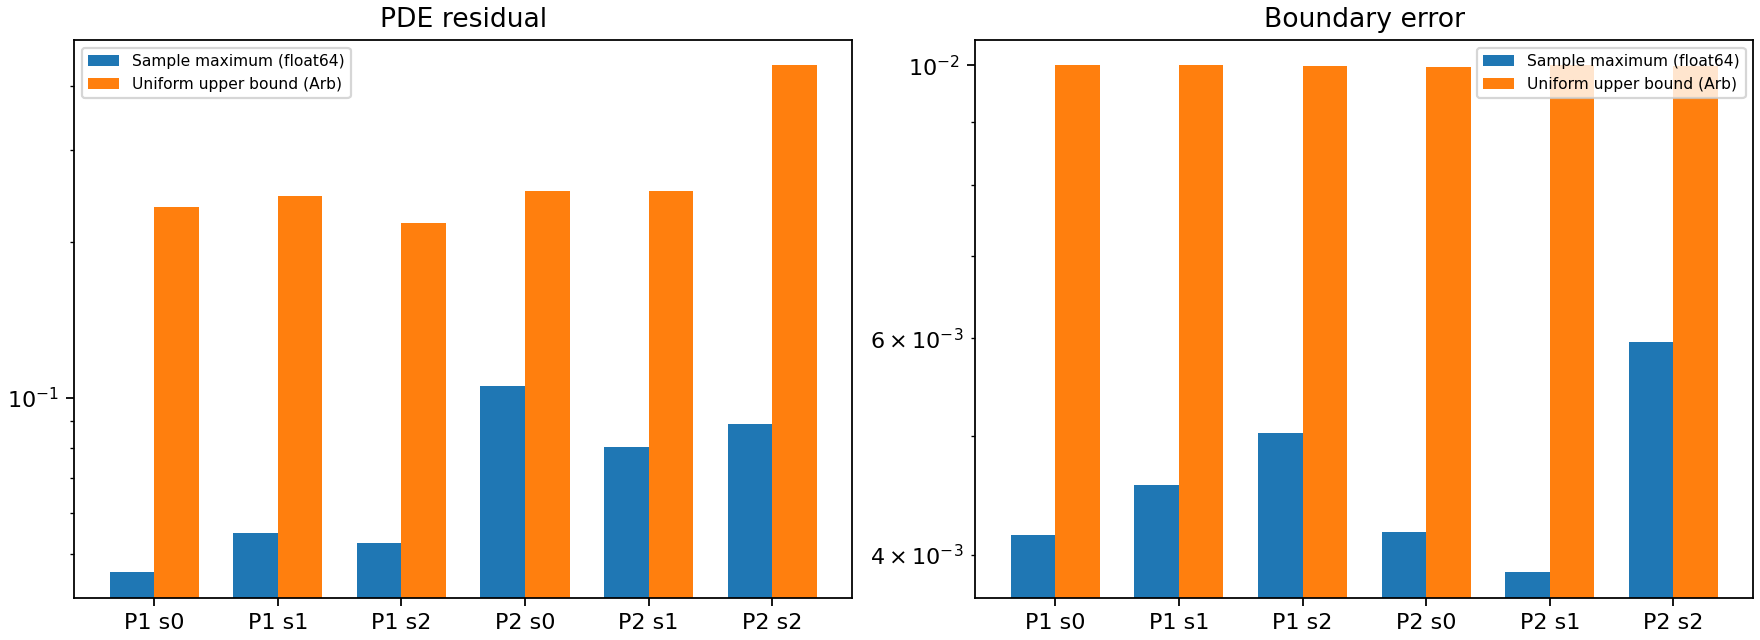

**refinement_P2_seed2/comparison.csv**

,pde_residual_uniform_upper,boundary_error_uniform_upper,u_error_uniform_upper_manufactured,solution_error_barrier_upper,solution_error_best_upper,stage,coverage_complete,residual_target_met,seconds_this_invocation,retained_leaves,...,boundary_target_met,stop_reason,discarded_boxes,boundary_arcs,new_certifications,cache_hits,child_boxes_processed,splits,parameters_sha256,error
0,0.437694,0.009989,0.046753,0.340781,0.046753,baseline,True,False,0.000000,14584,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.254972,0.009989,0.046753,0.262463,0.046753,stage_depth8,True,False,32.633563,15933,...,True,eligible_boxes_exhausted,850.0,1412.0,1850.0,0.0,1850.0,501.0,a9d7cb82e5a69ae7071692c4830aeeef5a9ebdf302d37b...,NaN
2,0.249951,0.009989,0.046753,0.259964,0.046753,stage_depth9,True,True,0.171658,15937,...,True,target_met,864.0,1412.0,10.0,0.0,10.0,6.0,a9d7cb82e5a69ae7071692c4830aeeef5a9ebdf302d37b...,NaN


**refinement_P2_seed2/solution_bounds.csv**

,model,stage,R,B,barrier_upper,direct_manufactured_upper,best_upper
0,P1_seed0,baseline,0.232851,0.010000,0.251273,0.107236,0.107236
1,P1_seed1,baseline,0.244416,0.010000,0.257192,0.114533,0.114533
2,P1_seed2,baseline,0.217256,0.009995,0.243049,0.110518,0.110518
3,P2_seed0,baseline,0.249930,0.009969,0.259935,0.053947,0.053947
4,P2_seed1,baseline,0.249997,0.009999,0.259997,0.065538,0.065538
5,P2_seed2,baseline,0.437694,0.009989,0.340781,0.046753,0.046753
6,P2_seed2,stage_depth9,0.249951,0.009989,0.259964,0.046753,0.046753


In [ ]:
import json
import pandas as pd
from IPython.display import display, Image, Markdown

def show_table(path, columns=None):
    if path.exists():
        df = pd.read_csv(path)
        display(Markdown(f"**{path.relative_to(OUT)}**"))
        display(df[columns] if columns else df)

if (PAPER_DIR / "RUN_STATUS.json").exists():
    print(json.dumps(json.loads((PAPER_DIR / "RUN_STATUS.json").read_text()), indent=2))
show_table(PAPER_DIR / "table_pilots.csv")
show_table(PAPER_DIR / "table_domain.csv")
for name in ["evaluation_depth.png", "benchmark_tradeoff.png", "uniform_bounds.png"]:
    if (PAPER_DIR / name).exists():
        display(Image(filename=str(PAPER_DIR / name)))

refinement = OUT / "refinement_P2_seed2"
show_table(refinement / "comparison.csv")
show_table(refinement / "solution_bounds.csv")

**extended_full/X1_near_critical/table_X1.csv**

,q,seed,u_relative_l2_sample,u_max_abs_sample,pde_residual_max_abs_sample,pde_residual_rmse,boundary_max_abs_sample,min_hessian_eigenvalue_sample,q_effective,delta,...,adaptive_mean_depth,adaptive_accepted_fraction,fixed_depth_seconds_per_point,arb_seconds_per_point,arb_det_error_upper_max,arb_pde_residual_upper_max,domain_residual_upper,domain_boundary_upper,domain_seconds,domain_boxes
0,0.70,0,0.002075,0.002923,0.079809,0.023382,0.003079,0.980790,0.70,0.30,...,25.158203,1.0,0.000224,0.000695,7.970093e-10,0.064344,1.525380e+00,0.012515,25.016575,1456
1,0.70,1,0.002681,0.004295,0.097340,0.019276,0.004364,0.978259,0.70,0.30,...,26.238281,1.0,0.000228,0.000720,3.457747e-10,0.058555,1.381563e+00,0.014296,26.286584,1456
2,0.70,2,0.003567,0.005848,0.090530,0.020037,0.006161,0.947007,0.70,0.30,...,21.345703,1.0,0.000145,0.000686,1.873565e-08,0.027399,1.542346e+00,0.016950,25.634942,1456
3,0.90,0,0.009532,0.011274,0.116676,0.024737,0.011686,1.001776,0.90,0.10,...,28.728516,1.0,0.000224,0.000690,2.413248e-11,0.099868,2.318350e+00,0.023632,25.550192,1456
4,0.90,1,0.011809,0.012280,0.157490,0.033612,0.013223,0.992377,0.90,0.10,...,23.664062,1.0,0.000151,0.000684,1.479029e-09,0.084311,1.794966e+00,0.027338,25.203962,1456
5,0.90,2,0.012742,0.014395,0.138095,0.023830,0.014956,0.985321,0.90,0.10,...,25.253906,1.0,0.000148,0.000688,2.805818e-10,0.069001,1.893373e+00,0.029946,33.076147,1456
6,0.95,0,0.008077,0.010502,0.071534,0.020061,0.011240,1.006455,0.95,0.05,...,24.359375,1.0,0.000225,0.000696,8.226049e-11,0.060384,3.959186e+00,0.028212,26.741477,1456
7,0.95,1,0.011628,0.013717,0.164045,0.047907,0.014464,0.962656,0.95,0.05,...,37.000000,1.0,0.000229,0.000771,5.040770e-08,0.108048,2.216378e+01,0.072771,31.576265,1456
8,0.95,2,0.013809,0.018267,0.358875,0.066976,0.019219,0.961001,0.95,0.05,...,74.390625,1.0,0.000525,0.000695,1.456899e-09,0.105472,3.714147e+03,0.229966,31.184839,1456
9,0.98,0,0.026841,0.034497,0.268124,0.057555,0.036558,0.933711,0.98,0.02,...,186.775391,1.0,0.001711,0.000679,1.789831e-08,0.110729,1.573189e+09,1.128299,36.012642,1456


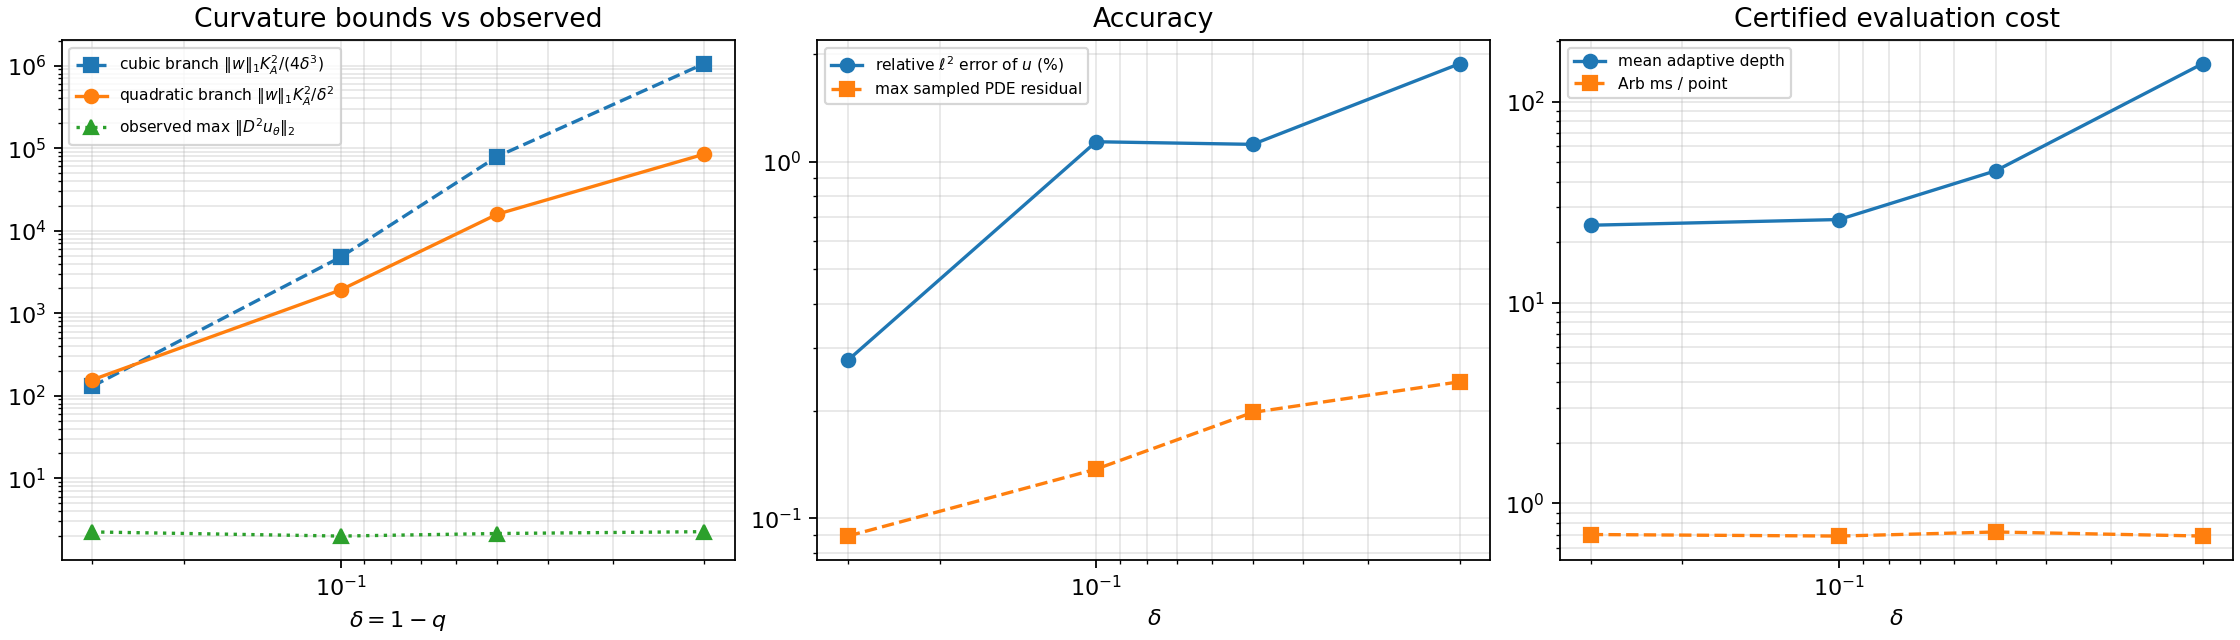

**extended_full/X2_explicit_icnn/table_X2.csv**

,problem,seed,equilibrium_parameters,icnn_parameters,equilibrium_u_relative_l2,icnn_u_relative_l2,equilibrium_pde_residual_max,icnn_pde_residual_max,equilibrium_boundary_max,icnn_boundary_max,equilibrium_eval_s_per_point_L32,icnn_eval_s_per_point,equilibrium_training_seconds,icnn_training_seconds,equilibrium_source
0,P1,0,207,211,0.002478,0.001256,0.045998,0.041939,0.004150,0.002215,0.000152,0.000008,70.425823,7.508298,/content/drive/MyDrive/MongeAmpere_Equilibrium...
1,P1,1,207,211,0.002932,0.002555,0.054896,0.028265,0.004564,0.003627,0.000154,0.000008,70.572831,7.297806,/content/drive/MyDrive/MongeAmpere_Equilibrium...
2,P1,2,207,211,0.003125,0.001535,0.052482,0.035595,0.005022,0.002605,0.000157,0.000008,70.772079,7.350503,/content/drive/MyDrive/MongeAmpere_Equilibrium...
3,P2,0,207,211,0.003001,0.002337,0.105285,0.067908,0.004173,0.002886,0.000151,0.000008,76.676717,7.305086,/content/drive/MyDrive/MongeAmpere_Equilibrium...
4,P2,1,207,211,0.002872,0.003625,0.080306,0.095127,0.003872,0.004453,0.000151,0.000008,71.707434,7.307480,/content/drive/MyDrive/MongeAmpere_Equilibrium...
5,P2,2,207,211,0.003144,0.003460,0.089144,0.093758,0.005954,0.004379,0.000155,0.000008,73.223053,7.315302,/content/drive/MyDrive/MongeAmpere_Equilibrium...
6,P3,0,207,211,0.000917,0.000676,0.259788,0.178399,0.005976,0.003359,0.000153,0.000008,75.065313,7.283604,/content/drive/MyDrive/MongeAmpere_Equilibrium...
7,P3,1,207,211,0.001251,0.000591,0.104305,0.176232,0.007935,0.003534,0.000152,0.000008,71.074392,7.399613,/content/drive/MyDrive/MongeAmpere_Equilibrium...
8,P3,2,207,211,0.000831,0.000688,0.228207,0.139637,0.005918,0.003961,0.000148,0.000008,69.455772,7.391906,/content/drive/MyDrive/MongeAmpere_Equilibrium...


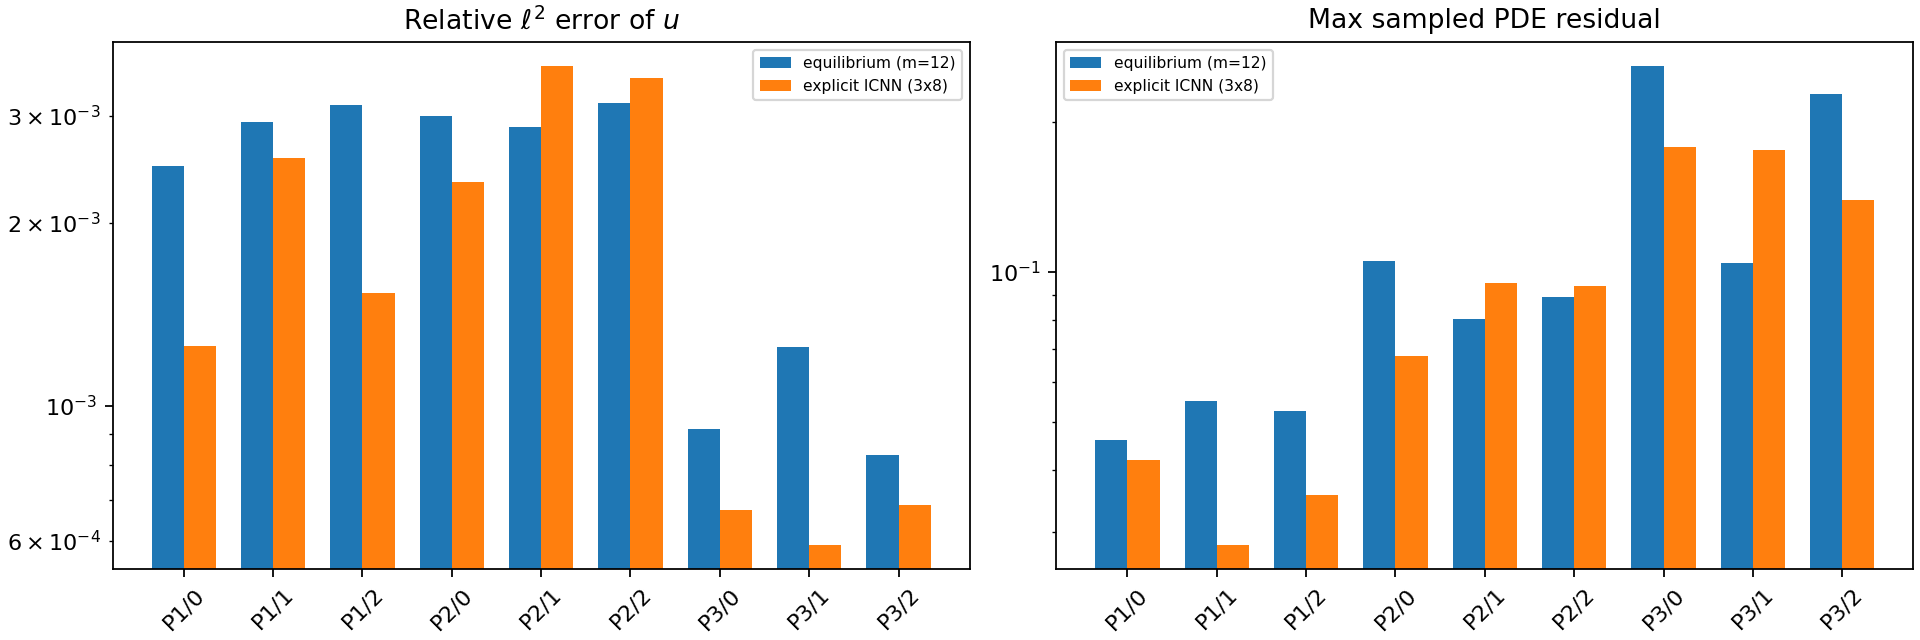

**extended_full/X3_harder_problems/table_X3.csv**

,problem,seed,u_relative_l2_sample,u_max_abs_sample,pde_residual_max_abs_sample,boundary_max_abs_sample,min_hessian_eigenvalue_sample,W_norm_infinity_float64,R_uniform,B_uniform,U_direct_uniform,barrier_upper,boxes,domain_seconds
0,P3,0,0.000917,0.005662,0.259788,0.005976,1.016050,0.669414,1.667871,0.009999,0.056988,0.655729,14769,185.165688
1,P3,1,0.001251,0.007436,0.104305,0.007935,1.016875,0.676544,1.297927,0.011338,0.056082,0.580971,14760,172.931224
2,P3,2,0.000831,0.005317,0.228207,0.005918,1.005519,0.673889,1.342933,0.009996,0.056643,0.589421,14769,163.328240
3,P4,0,0.022381,0.008210,0.113543,0.006537,0.056139,0.452122,0.249915,0.009998,0.269519,0.259956,969,16.304100
4,P4,1,0.078555,0.030509,0.271148,0.018876,0.105549,0.380777,0.350348,0.019326,0.255152,0.315277,3123,58.524142
5,P4,2,0.057122,0.031521,0.360951,0.033867,0.036997,0.632394,0.463862,0.035558,0.445202,0.376095,2370,76.041290


**extended_full/X4_tightness/table_X4.csv**

,problem,seed,evaluated_boxes,retained_boxes,max_level,R_uniform,seconds,R_over_final
0,P1,0,100,78,4,3.064351,0.195978,36.824159
1,P1,0,252,188,4,1.850667,0.490938,22.239376
2,P1,0,500,369,5,0.878522,0.984118,10.557150
3,P1,0,1000,739,5,0.683432,1.933721,8.212773
4,P1,0,2000,1474,6,0.356557,3.907206,4.284733
5,P1,0,4000,2967,6,0.295073,7.719079,3.545872
6,P1,0,8002,5925,7,0.165379,15.618076,1.987351
7,P1,0,16000,11912,7,0.138816,30.999159,1.668148
8,P1,0,32001,23809,9,0.083216,63.077331,1.000000
9,P1,0,32001,23809,9,0.083216,63.082111,1.000000


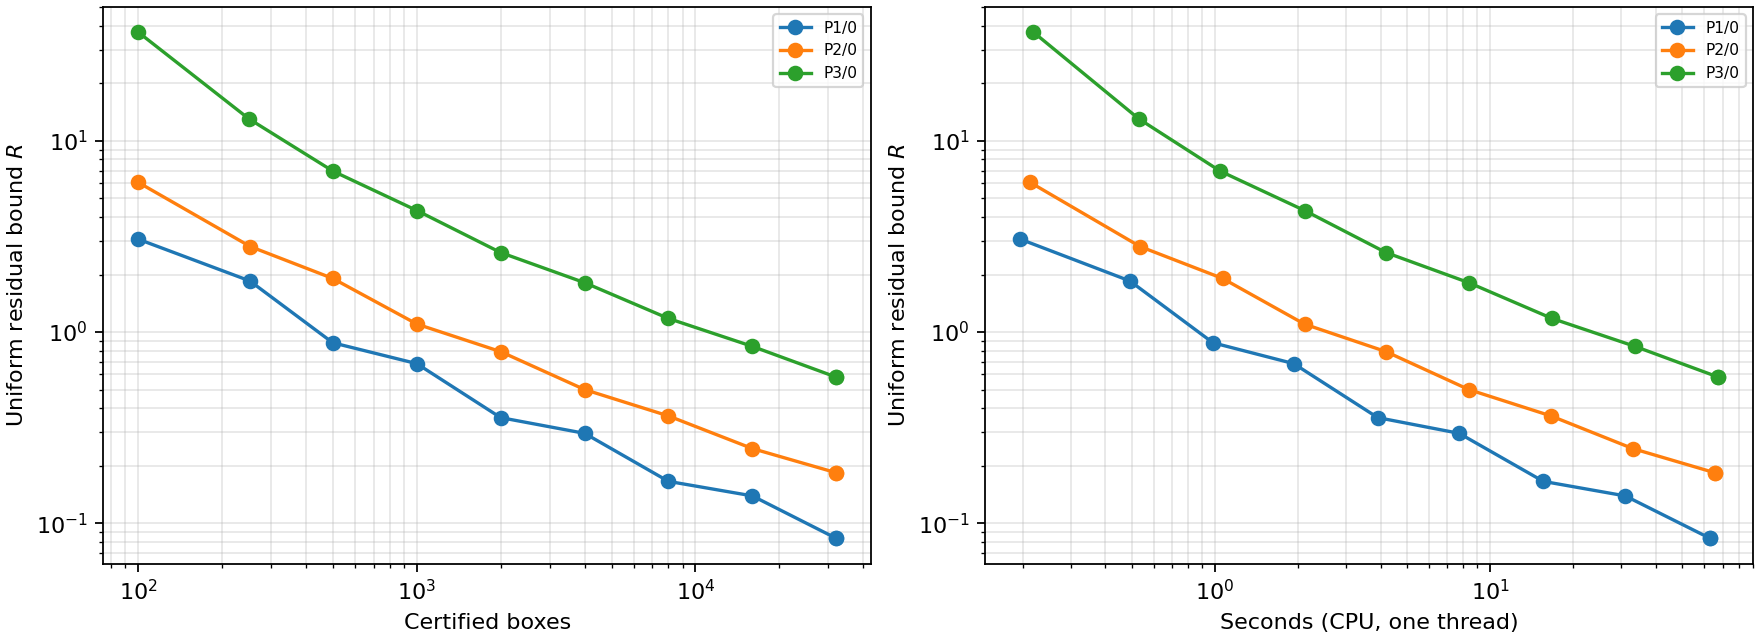

**extended_full/X5_fd_baseline/table_X5.csv**

,problem,N,h,unknowns,bfo_iterations,newton_iterations,final_discrete_residual,u_max_abs_error_nodes,u_relative_l2_nodes,seconds
0,P1,16,0.125000,193,43,2,1.065814e-14,5.551115e-17,5.911849e-17,0.006047
1,P1,32,0.062500,793,42,2,1.421085e-13,1.110223e-16,4.957571e-17,0.012322
2,P1,64,0.031250,3205,42,2,3.410605e-13,1.110223e-16,5.799301e-17,0.048062
3,P1,128,0.015625,12849,41,2,1.364242e-12,1.665335e-16,8.220548e-17,0.388349
4,P2,16,0.125000,193,18,2,2.309264e-14,1.659205e-03,3.293691e-03,0.003495
5,P2,32,0.062500,793,19,2,1.612044e-13,4.043635e-04,7.571212e-04,0.009070
6,P2,64,0.031250,3205,19,2,5.848655e-13,9.957674e-05,1.818309e-04,0.034158
7,P2,128,0.015625,12849,19,3,2.228440e-12,2.465180e-05,4.461687e-05,0.373014
8,P3,16,0.125000,193,15,2,8.970602e-14,2.924337e-03,1.470352e-03,0.003234
9,P3,32,0.062500,793,17,2,4.058975e-13,7.172263e-04,3.498251e-04,0.008230


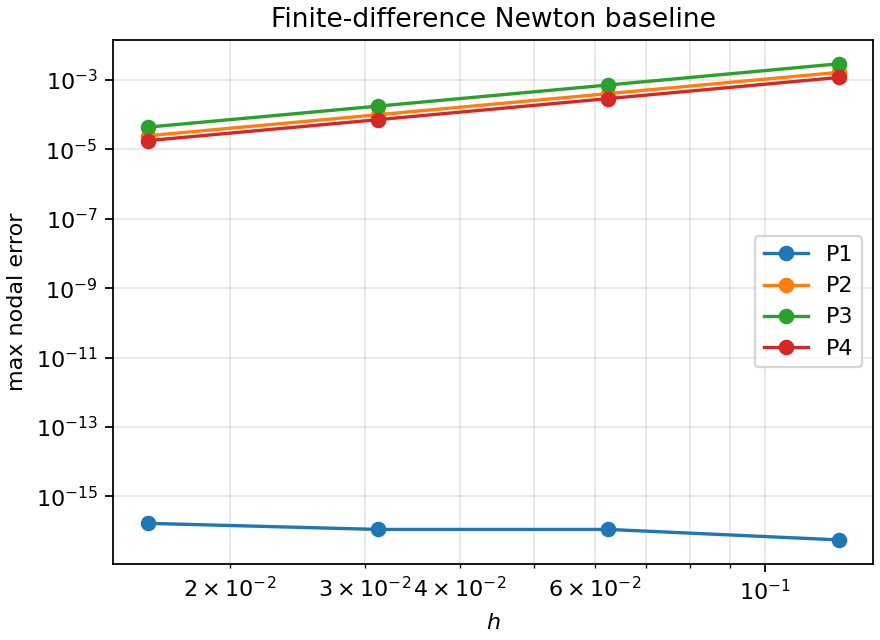

**extended_full/X6_width_scaling/table_X6.csv**

,seed,u_relative_l2_sample,u_max_abs_sample,pde_residual_max_abs_sample,pde_residual_rmse,boundary_max_abs_sample,min_hessian_eigenvalue_sample,q_effective,delta,w_norm_1,...,C2_quadratic_branch,C2_cubic_branch,C2_theorem,S_gamma_max_sample,float64_seconds_per_point,arb_point_seconds,arb_box_seconds,width,trainable_parameters,training_seconds
0,0,0.003001,0.003804,0.105285,0.018296,0.004173,0.980699,0.646561,0.353439,2.132583,...,120.195252,85.018283,85.018283,0.385737,0.000158,0.000674,0.001897,12,207,71.236467
1,0,0.003126,0.003854,0.088605,0.017898,0.004325,1.002301,0.641718,0.358282,1.766009,...,126.951631,88.583598,88.583598,0.378819,0.000452,0.001735,0.005699,24,699,111.135035
2,0,0.002652,0.003203,0.071733,0.012024,0.003378,0.995870,0.660735,0.339265,1.586926,...,213.479023,157.309724,157.309724,0.398077,0.001458,0.004972,0.021418,48,2547,199.150744


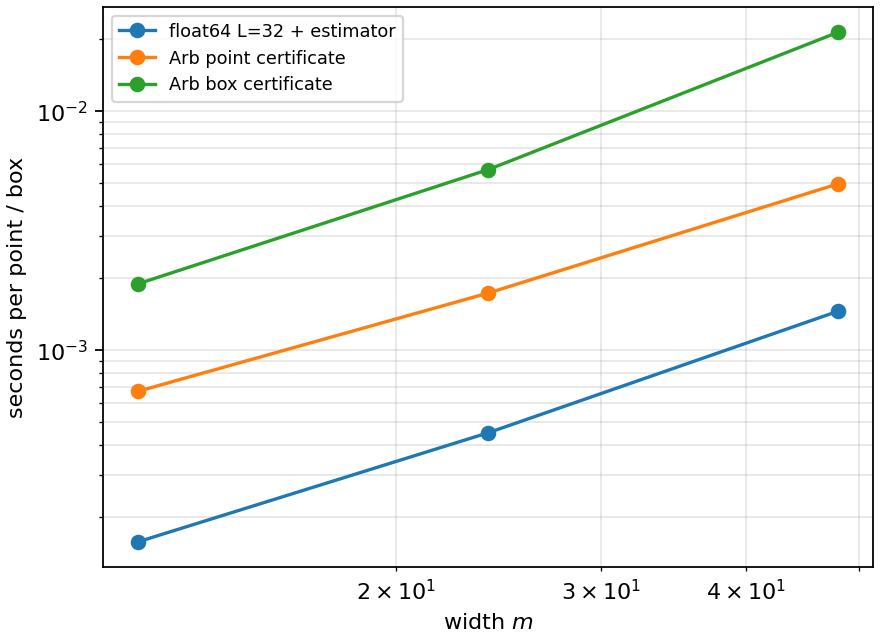

In [ ]:
for exp, folder in [("X1", "X1_near_critical"), ("X2", "X2_explicit_icnn"), ("X3", "X3_harder_problems"),
                    ("X4", "X4_tightness"), ("X5", "X5_fd_baseline"), ("X6", "X6_width_scaling")]:
    show_table(EXTENDED_DIR / folder / f"table_{exp}.csv")
    figure = EXTENDED_DIR / folder / f"{folder}.png"
    if figure.exists():
        display(Image(filename=str(figure)))

## Download

Creates one ZIP with all outputs of this run (trained parameters, certificates, tables, figures, configurations and hashes).

In [ ]:
import shutil
archive = shutil.make_archive(str(OUT), "zip", root_dir=OUT)
print("Archive:", archive)
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    pass

Archive: /content/drive/MyDrive/MongeAmpere_Equilibrium/results_full1.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Scope

The certificates concern evaluation of fixed trained networks: they are rigorous for the exact real model defined by the saved binary64 parameters (`code/METHODS.txt`). They do not establish convergence of training. Sample maxima are not domain suprema; uniform statements come only from the complete covers. Timing comparisons are made within cohorts of equal size and target.